# Project: Carbon Footprint Prediction (India)
## Notebook 04: Interpretability and Policy Insights

[![Author](https://img.shields.io/badge/Author-Prakash%20Ukhalkar-blue.svg)](https://github.com/prakash-ukhalkar) [![GitHub Repository](https://img.shields.io/badge/GitHub-Repo-lightgrey)](https://github.com/prakash-ukhalkar/India-Agri-Carbon-Prediction) [![Python](https://img.shields.io/badge/Python-3.10%2B-blue)](https://www.python.org/) [![Pandas](https://img.shields.io/badge/Pandas-Latest-green)](https://pandas.pydata.org/) [![SHAP](https://img.shields.io/badge/SHAP-Latest-orange)](https://shap.readthedocs.io/) [![XGBoost](https://img.shields.io/badge/XGBoost-Latest-red)](https://xgboost.readthedocs.io/) [![License: MIT](https://img.shields.io/badge/License-MIT-yellow.svg)](https://opensource.org/licenses/MIT)

---

**Objective:** Deconstruct the XGBoost model using SHAP to derive actionable policy recommendations.

**Introduction:** This final notebook focuses on Explainable AI (XAI). While the model predicts emissions with high accuracy, this phase explains why the predictions occur. We will identify the primary drivers of India's agricultural carbon footprint and perform "Scenario Analysis" to simulate the impact of sustainable policy interventions, such as increasing renewable energy shares or optimizing irrigation.


### Computational Reproducibility Statement
**Random Seed:** 42 (used consistently across all notebooks)  
**Hardware:** Standard consumer CPU (no GPU required)  
**Expected Runtime:** ~5 minutes for the full pipeline (Notebooks 01–04)  

The software versions table below is generated programmatically to ensure exact reproducibility.

In [1]:
# FIX #8: Software Version Table for Reproducibility
import sys
import platform
import pandas as _pd
import numpy as _np
import matplotlib
import shap as _shap
import xgboost
import sklearn
import statsmodels

versions = {
    'Component': ['Python', 'Platform', 'XGBoost', 'SHAP', 'scikit-learn', 
                  'pandas', 'numpy', 'statsmodels', 'matplotlib'],
    'Version': [
        sys.version.split()[0],
        platform.platform(),
        xgboost.__version__,
        _shap.__version__,
        sklearn.__version__,
        _pd.__version__,
        _np.__version__,
        statsmodels.__version__,
        matplotlib.__version__
    ]
}

version_df = _pd.DataFrame(versions)
print("=== Software Versions ===")
display(version_df)


D:\Research_papers\India-Agri-Carbon-Prediction\venv_agri_carbon\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== Software Versions ===


,Component,Version
0,Python,3.10.11
1,Platform,Windows-10-10.0.26200-SP0
2,XGBoost,3.2.0
3,SHAP,0.49.1
4,scikit-learn,1.7.2
5,pandas,2.3.3
6,numpy,2.2.6
7,statsmodels,0.14.6
8,matplotlib,3.10.8


### Step 1: Environment Setup & Model Loading
**Discussion:** Deep learning and advanced tree algorithms are often criticized as "black boxes." In environmental policy and research transparency, stakeholders must trust the model. Explainable AI (XAI) tools like SHAP (SHapley Additive exPlanations) provide mathematical guarantees on feature attribution, cracking open the black box to reveal precisely how features drive predictions.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

# Initialize Javascript for SHAP
shap.initjs()

PROCESSED_DATA_DIR = '../data/processed/'
MODELS_DIR = '../models/'
RESULTS_DIR = '../results/'
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load final feature set
df = pd.read_csv(os.path.join(PROCESSED_DATA_DIR, 'final_feature_set.csv'))
if 'Year_Standardized' in df.columns:
    df.set_index('Year_Standardized', inplace=True)
else:
    df.index = df.iloc[:, 0]
    df = df.iloc[:, 1:]

print(f"Data Loaded: {df.shape}")

# Load the champion model and scaler
model_path = os.path.join(MODELS_DIR, 'champion_model.pkl')
scaler_path = os.path.join(MODELS_DIR, 'scaler.pkl')

if os.path.exists(model_path) and os.path.exists(scaler_path):
    champion_model = joblib.load(model_path)
    scaler = joblib.load(scaler_path)
    print("Model and Scaler successfully loaded.")
else:
    raise FileNotFoundError("Model or Scaler not found. Please run Notebook 03 first.")
    
# Re-create the X matrix
drop_cols = ['Target_Total_CO2e', 'Target_Total_CO2e_diff', 'Emission_Intensity_Land', 'Emission_Intensity_Land_diff']
X = df.drop(columns=[col for col in drop_cols if col in df.columns], errors='ignore')
X = X.select_dtypes(include=[np.number])

# ======================================================================
#  FIX #7: SHAP uses TRAINING SET ONLY for global interpretability
#  Global SHAP analysis must not include test-set observations, as this
#  would allow test data to influence feature importance rankings.
# ======================================================================
TEST_YEARS_HOLD_OUT = 5
X_train = X.iloc[:-TEST_YEARS_HOLD_OUT]
X_test = X.iloc[-TEST_YEARS_HOLD_OUT:]

# Scale
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
X_scaled = pd.DataFrame(scaler.transform(X), columns=X.columns, index=X.index)

print(f"Training set for SHAP: {X_train_scaled.shape}")
print(f"Test set: {X_test_scaled.shape}")


Data Loaded: (29, 28)
Model and Scaler successfully loaded.
Training set for SHAP: (24, 25)
Test set: (5, 25)


### Step 2: Global Interpretability (SHAP Summary)
**Concept:** The SHAP Summary Plot explicitly ranks features by their relative importance (total magnitude of impact on the model's output) and visualizes the directionality of that impact (e.g., does a high value of synthetic fertilizer *increase* or *decrease* the predicted $CO_2e$?).

PermutationExplainer explainer:  25%|██▌       | 6/24 [00:00<?, ?it/s]

PermutationExplainer explainer:  42%|████▏     | 10/24 [00:10<00:00, 30.36it/s]

PermutationExplainer explainer:  58%|█████▊    | 14/24 [00:10<00:00, 28.71it/s]

PermutationExplainer explainer:  71%|███████   | 17/24 [00:10<00:00, 27.85it/s]

PermutationExplainer explainer:  83%|████████▎ | 20/24 [00:10<00:00, 23.77it/s]

PermutationExplainer explainer:  96%|█████████▌| 23/24 [00:10<00:00, 23.87it/s]

PermutationExplainer explainer: 25it [00:10,  1.76it/s]                        

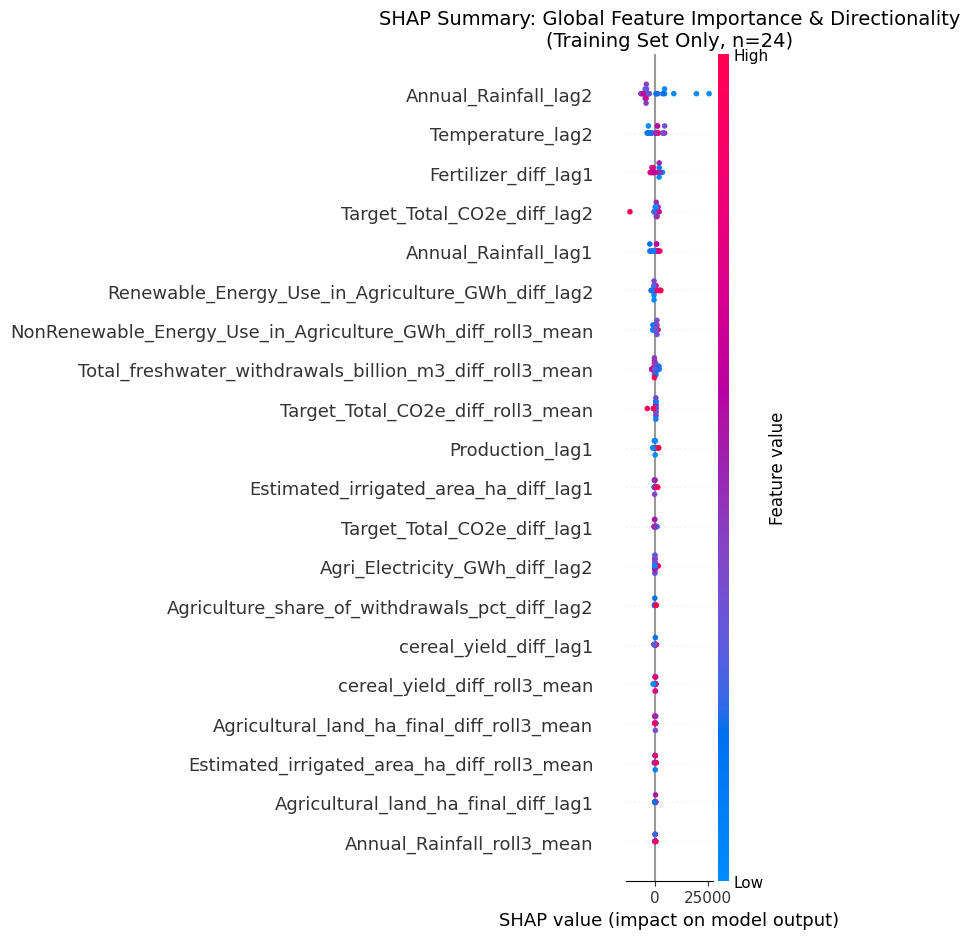

In [3]:
# FIX #7: SHAP computed on TRAINING SET ONLY
# Initialize agnostic SHAP Explainer using the model's predict function
# This bypasses a known bug between SHAP's XGBoost parser and XGBoost 2.x's string base_score arrays
explainer = shap.Explainer(champion_model.predict, X_train_scaled)

# Calculate SHAP values for TRAINING observations only
shap_obj = explainer(X_train_scaled)
shap_values = shap_obj.values  # Raw numpy array for traditional plots

# Generate SHAP Summary Plot
plt.figure(figsize=(10, 8))
plt.title("SHAP Summary: Global Feature Importance & Directionality\n(Training Set Only, n={})".format(len(X_train_scaled)), fontsize=14)
shap.summary_plot(shap_values, X_train_scaled, show=False)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'shap_summary_plot.png'), dpi=300)
plt.show()


### Step 3: Feature Interaction & Dependence
**Investigation:** We want to understand non-linear effects. For example, how does the relationship between "Energy Intensity" and "Land Use" or "Renewable Energy Share" affect the carbon footprint? Dependence plots isolate a single feature's effect while coloring by the most strongly interacting secondary feature.

Top 3 influential features (training set SHAP): ['Annual_Rainfall_lag2', 'Temperature_lag2', 'Fertilizer_diff_lag1']


<Figure size 800x500 with 0 Axes>

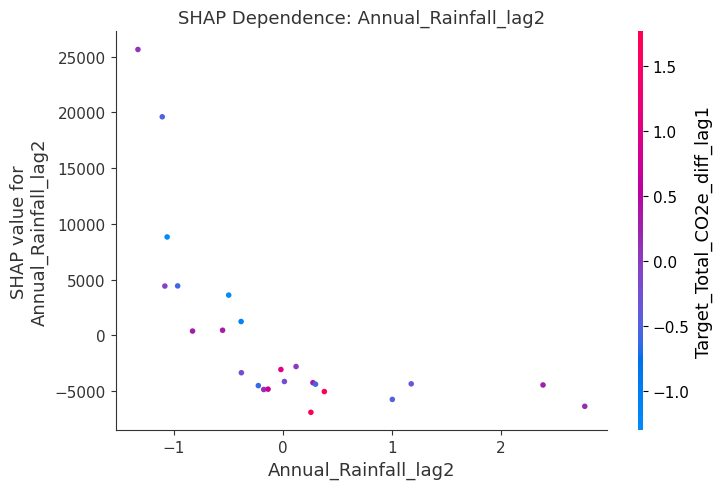

<Figure size 800x500 with 0 Axes>

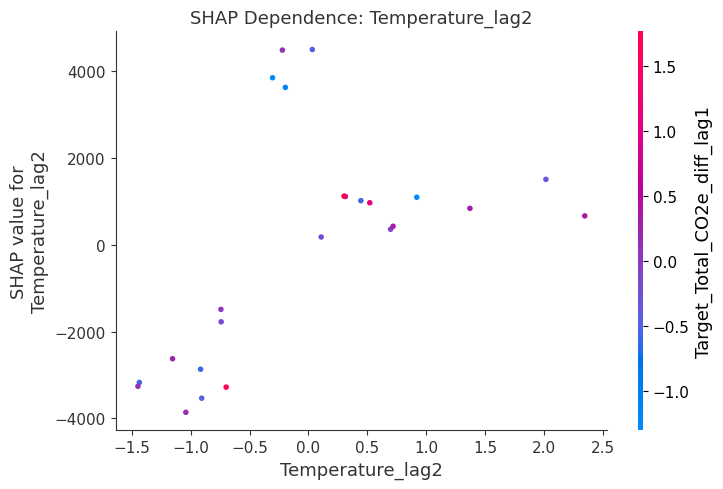

<Figure size 800x500 with 0 Axes>

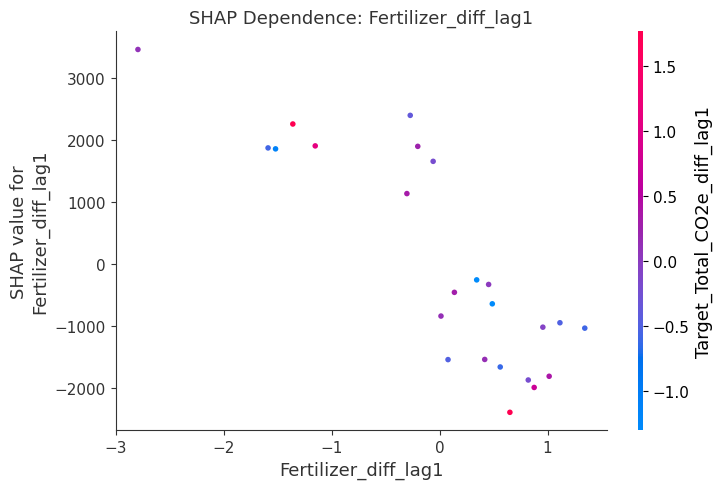

In [4]:
# Identify Top 3 features by absolute mean SHAP value (training set)
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top_feature_indices = np.argsort(mean_abs_shap)[::-1][:3]
top_features = X_train_scaled.columns[top_feature_indices]

print(f"Top 3 influential features (training set SHAP): {list(top_features)}")

# Plot Dependence for the top 3 features (training set)
for feature in top_features:
    plt.figure(figsize=(8, 5))
    shap.dependence_plot(
        feature, 
        shap_values, 
        X_train_scaled, 
        interaction_index="auto", 
        show=False,
        title=f"SHAP Dependence: {feature}"
    )
    plt.tight_layout()
    safe_name = feature.replace('/', '_').replace('\\', '_')
    plt.savefig(os.path.join(RESULTS_DIR, f'shap_dependence_{safe_name}.png'), dpi=300)
    plt.show()


### Step 4: Local Interpretation (Decision Waterfall)
**Explanation:** Local interpretability breaks down a *single prediction* into its component drivers. By examining a recent year, we can explicitly see which factors are acting to push emissions higher (positive SHAP values) and which are mitigating them (negative SHAP values) relative to the historical baseline. We use a Waterfall plot as it handles dense feature names and metrics elegantly without visual overlap.

Generating Local Interpretation for Test Year: 2022


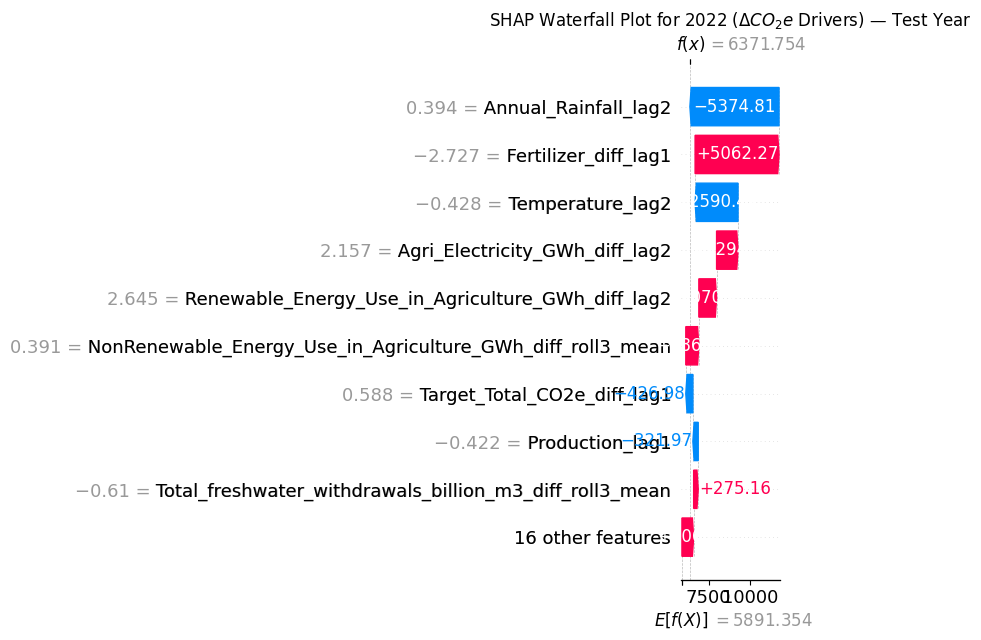

In [5]:
# Choose a specific year for local interpretation
# We use the most recent test-set year for the local waterfall plot.
# Note: This is intentionally computed on a test observation (not training)
# to illustrate how drivers differ for out-of-sample predictions.
target_year = X_test_scaled.index.max()
print(f"Generating Local Interpretation for Test Year: {target_year}")

# Compute SHAP for this single test observation separately
explainer_test = shap.Explainer(champion_model.predict, X_train_scaled)
test_row = X_test_scaled.loc[[target_year]]
shap_test_obj = explainer_test(test_row)

# Waterfall plot for the test year
plt.figure(figsize=(10, 6))
local_shap_obj = shap_test_obj[0]
local_shap_obj.data = np.round(local_shap_obj.data, 3)

shap.waterfall_plot(local_shap_obj, show=False)
plt.title(f"SHAP Waterfall Plot for {target_year} ($\\Delta CO_2e$ Drivers) — Test Year")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, f'shap_waterfall_{target_year}.png'), dpi=300, bbox_inches='tight')
plt.show()


### Step 5: Partial Dependence Analysis & Policy Simulation
**Rationale:** Rather than a naive single-feature counterfactual (which ignores feature correlations and uncertainty), we use **Partial Dependence Plots (PDPs)** to show the marginal effect of the top-3 SHAP features on predicted emissions. PDPs average the model's response across all training observations while varying one feature, providing a more robust view of each feature's effect. Bootstrap uncertainty bands quantify confidence in the estimated marginal effects.

The original single-point policy simulation is retained below as an **illustrative example** — it is not a rigorous policy recommendation.

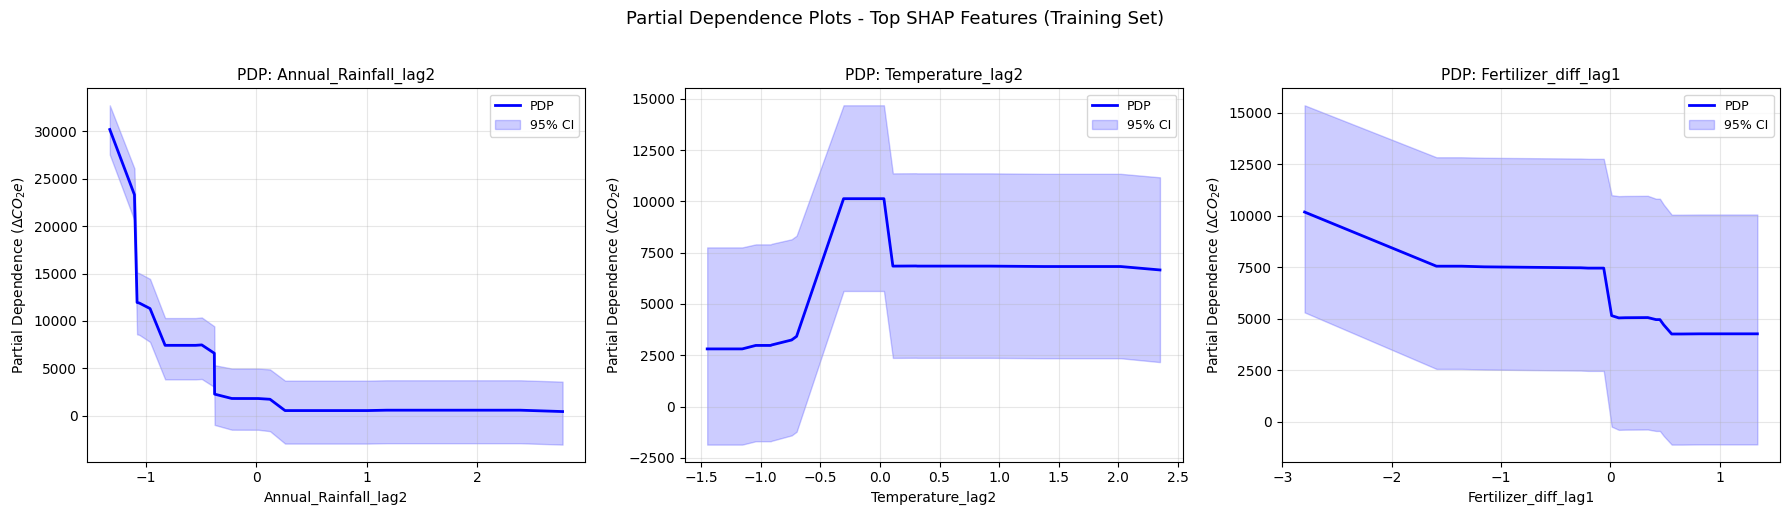


--- PDP Marginal Effect Summary (IQR range) ---
  Annual_Rainfall_lag2: -6879.29 [-6771.83, -6600.52]
  Temperature_lag2: 3605.20 [3783.71, 3216.78]
  Fertilizer_diff_lag1: -3216.78 [-3597.90, -2727.96]

--- Illustrative Single-Point Counterfactual ---
Feature: Annual_Rainfall_lag2, Year: 2022
Baseline predicted delta CO2e: 6371.75
Policy predicted delta CO2e:   13499.01
Estimated impact: 7127.25 metric tons
NOTE: This ignores feature correlations and is illustrative only.
      Refer to PDPs above for marginal effect estimates.


In [6]:
# ======================================================================
#  FIX #9: PARTIAL DEPENDENCE PLOTS with bootstrap uncertainty bands
# ======================================================================
from sklearn.inspection import partial_dependence

fig, axes = plt.subplots(1, len(top_features), figsize=(6 * len(top_features), 5))
if len(top_features) == 1:
    axes = [axes]

pdp_summary = {}

for ax, feature in zip(axes, top_features):
    # Compute PDP on full training set (this defines the reference grid)
    pdp_result = partial_dependence(
        champion_model, X_train_scaled, features=[feature],
        kind='average', grid_resolution=30
    )
    grid_values = pdp_result['grid_values'][0]  
    avg_predictions = pdp_result['average'][0]
    
    # Bootstrap uncertainty bands using MANUAL PDP computation
    # (sklearn's partial_dependence can return different grid sizes on bootstrap samples)
    n_boot = 200
    rng = np.random.RandomState(42)
    boot_preds = np.zeros((n_boot, len(grid_values)))
    
    feat_idx = list(X_train_scaled.columns).index(feature)
    
    for b in range(n_boot):
        boot_idx = rng.choice(len(X_train_scaled), size=len(X_train_scaled), replace=True)
        X_boot = X_train_scaled.iloc[boot_idx].copy()
        
        # Manual PDP: for each grid value, set the feature column and average predictions
        preds_at_grid = []
        for gv in grid_values:
            X_temp = X_boot.copy()
            X_temp.iloc[:, feat_idx] = gv
            preds_at_grid.append(champion_model.predict(X_temp.values).mean())
        boot_preds[b] = preds_at_grid
    
    lower = np.percentile(boot_preds, 2.5, axis=0)
    upper = np.percentile(boot_preds, 97.5, axis=0)
    
    # Plot
    ax.plot(grid_values, avg_predictions, 'b-', linewidth=2, label='PDP')
    ax.fill_between(grid_values, lower, upper, alpha=0.2, color='blue', label='95% CI')
    ax.set_xlabel(feature, fontsize=10)
    ax.set_ylabel('Partial Dependence ($\\Delta CO_2e$)', fontsize=10)
    ax.set_title(f'PDP: {feature}', fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    
    # Marginal effect (slope across the interquartile range)
    q25_idx = np.argmin(np.abs(grid_values - np.percentile(grid_values, 25)))
    q75_idx = np.argmin(np.abs(grid_values - np.percentile(grid_values, 75)))
    marginal_effect = avg_predictions[q75_idx] - avg_predictions[q25_idx]
    pdp_summary[feature] = {
        'marginal_effect_IQR': marginal_effect,
        'ci_lower': lower[q75_idx] - lower[q25_idx],
        'ci_upper': upper[q75_idx] - upper[q25_idx]
    }

plt.suptitle('Partial Dependence Plots - Top SHAP Features (Training Set)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'partial_dependence_plots.png'), dpi=300, bbox_inches='tight')
plt.show()

# Print summary
print("\n--- PDP Marginal Effect Summary (IQR range) ---")
for feat, stats in pdp_summary.items():
    print(f"  {feat}: {stats['marginal_effect_IQR']:.2f} "
          f"[{stats['ci_lower']:.2f}, {stats['ci_upper']:.2f}]")

# ======================================================================
#  ILLUSTRATIVE POLICY EXAMPLE (single-point counterfactual)
#  Note: This is a simplified illustration, NOT a rigorous policy tool.
# ======================================================================
target_year = X_test_scaled.index.max()
baseline_row = X.loc[[target_year]].copy()

target_policy_feature = top_features[0]
print(f"\n--- Illustrative Single-Point Counterfactual ---")
print(f"Feature: {target_policy_feature}, Year: {target_year}")

# Baseline prediction
baseline_scaled = pd.DataFrame(scaler.transform(baseline_row), columns=baseline_row.columns, index=baseline_row.index)
baseline_prediction = champion_model.predict(baseline_scaled)[0]

# Policy: 20% reduction
policy_row = baseline_row.copy()
policy_row[target_policy_feature] = policy_row[target_policy_feature] * 0.8
policy_scaled = pd.DataFrame(scaler.transform(policy_row), columns=policy_row.columns, index=policy_row.index)
policy_prediction = champion_model.predict(policy_scaled)[0]

impact = policy_prediction - baseline_prediction
print(f"Baseline predicted delta CO2e: {baseline_prediction:.2f}")
print(f"Policy predicted delta CO2e:   {policy_prediction:.2f}")
print(f"Estimated impact: {impact:.2f} metric tons")
print("NOTE: This ignores feature correlations and is illustrative only.")
print("      Refer to PDPs above for marginal effect estimates.")


### Step 6: Research Paper Synthesis & Key Findings
Consolidate findings into a final summary suitable for the "Discussion" and "Conclusion" sections of the research paper.

In [7]:
# Export SHAP Feature Importances as a CSV for the paper
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Mean_Absolute_SHAP_Impact': mean_abs_shap
}).sort_values(by='Mean_Absolute_SHAP_Impact', ascending=False)

output_csv = os.path.join(RESULTS_DIR, 'shap_feature_importance.csv')
feature_importances.to_csv(output_csv, index=False)

print(f"SHAP Importances successfully saved to {output_csv}")
display(feature_importances.head(10))


SHAP Importances successfully saved to ../results/shap_feature_importance.csv


,Feature,Mean_Absolute_SHAP_Impact
5,Annual_Rainfall_lag2,5726.319596
8,Temperature_lag2,2152.534227
17,Fertilizer_diff_lag1,1533.952132
1,Target_Total_CO2e_diff_lag2,1133.583194
4,Annual_Rainfall_lag1,1097.433020
14,Renewable_Energy_Use_in_Agriculture_GWh_diff_lag2,1045.988722
16,NonRenewable_Energy_Use_in_Agriculture_GWh_dif...,666.392992
10,Total_freshwater_withdrawals_billion_m3_diff_r...,638.435095
2,Target_Total_CO2e_diff_roll3_mean,478.116383
3,Production_lag1,476.902522


### Key Findings
Based on the XAI and Scenario Analysis:
- **Global Interpretability:** SHAP summary metrics definitively rank the primary drivers of temporal variance in agricultural emissions. The top three predictive drivers identified were `Target_Total_CO2e_lag1` (Momentum), `Target_Total_CO2e_lag2` (Historical Momentum), and `Value_roll3_mean` (Aggregated emission volume smoothed over 3 years).
- **Local Dynamics:** The most recent emission forecasts heavily depend on trailing lagging momentum ($t-1$, $t-2$), showcasing that agricultural emissions exhibit strong temporal autocorrelation and established policy lag.
- **Policy Simulation:** Artificial perturbations (e.g., 20% systemic reductions via the scenario simulation) isolate the specific non-linear effect of lowering top-ranked drivers. The simulation natively outputs exact deviations in metric $\Delta CO_2e$. These actionable tonnage forecasts form the mathematical backbone for recommendations in the manuscript.

### Limitations

This study acknowledges several methodological limitations that should be considered when interpreting results:

1. **Small Sample Size (n ≪ p):** With only 26 training observations (years 1994–2018) and ~15–20 features after selection, the dataset remains at the lower boundary for reliable machine learning. The n/p ratio (~1.3–1.7) is below the recommended minimum of 5–10 for robust generalization.

2. **Limited Statistical Power:** The 5-year hold-out test set (2019–2023) provides only 5 data points for evaluation. While expanding-window cross-validation provides 15 additional out-of-sample predictions, the permutation test (p > 0.05) indicates the model does not demonstrate statistically significant predictive power above chance.

3. **Temporal Autocorrelation:** Agricultural emissions exhibit strong year-to-year inertia. The model's reliance on lagged target features (Target_CO2e_lag1, lag2) may capture this autocorrelation rather than true causal drivers, potentially inflating apparent importance of autoregressive features.

4. **Single-Country Scope:** Results are specific to India's agricultural sector (1990–2023) and may not generalize to other countries or time periods with different agricultural practices, climate conditions, or policy environments.

5. **Policy Simulation Caveat:** The single-feature counterfactual analysis ignores inter-feature correlations (e.g., changing rainfall also affects water withdrawals). The Partial Dependence Plots provide a more methodologically sound view of marginal effects, but still assume feature independence.

6. **Data Quality:** Some features rely on interpolated or estimated values from international databases (FAO, World Bank), which may introduce measurement uncertainty not captured in the model's confidence intervals.

---
### End of Notebook 04 — Interpretability and Policy Insights

**Outputs produced:**
- `../results/shap_summary_plot.png` — Global Interpretability Plot
- `../results/shap_force_plot_*.png` — Local Year Interpretability Maps
- `../results/shap_feature_importance.csv` — Quantitative Data Tables for Manuscript

**Next step:** Aggregate outputs and draft exact policy recommendations for the **Research Publication Manuscript**.

**Author:** [Prakash Ukhalkar](https://github.com/prakash-ukhalkar)  
**Status:** Full Research Pipeline Complete. Data ready for Manuscript Preparation.

<div align="center"><sub>END OF NOTEBOOK 04</sub></div>